In [ ]:
#building makemore 
#implementation of a bigram character level language model. -> modern transformer model.
# character level tokenization 


In [73]:
#requirments
import numpy as np 
import torch
import matplotlib.pyplot as plt
%matplotlib inline


# Data 

In [10]:
data = open("names.txt", "r").read().splitlines()
type(data)
data[:10]



['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [12]:
len(data)


32033

In [13]:
min(len(v) for v in data)

2

In [14]:
max(len(v) for v in data)

15

#Bigram Language Model


In [37]:
#individual character bigrams 
c = {}
for w in data: 
    chs = ["<S>"] + list(w) + ["<E>"]
    for ch1,ch2 in zip(chs,chs[1:]):
        bigram = (ch1,ch2)
        c[bigram]= c.get(bigram,0) +1 


    


In [43]:
#statictics of the entire dataset
sorted(c.items(), key = lambda kv: kv[1])

[(('q', 'r'), 1),
 (('d', 'z'), 1),
 (('p', 'j'), 1),
 (('q', 'l'), 1),
 (('p', 'f'), 1),
 (('q', 'e'), 1),
 (('b', 'c'), 1),
 (('c', 'd'), 1),
 (('m', 'f'), 1),
 (('p', 'n'), 1),
 (('w', 'b'), 1),
 (('p', 'c'), 1),
 (('h', 'p'), 1),
 (('f', 'h'), 1),
 (('b', 'j'), 1),
 (('f', 'g'), 1),
 (('z', 'g'), 1),
 (('c', 'p'), 1),
 (('p', 'k'), 1),
 (('p', 'm'), 1),
 (('x', 'n'), 1),
 (('s', 'q'), 1),
 (('k', 'f'), 1),
 (('m', 'k'), 1),
 (('x', 'h'), 1),
 (('g', 'f'), 1),
 (('v', 'b'), 1),
 (('j', 'p'), 1),
 (('g', 'z'), 1),
 (('v', 'd'), 1),
 (('d', 'b'), 1),
 (('v', 'h'), 1),
 (('h', 'h'), 1),
 (('g', 'v'), 1),
 (('d', 'q'), 1),
 (('x', 'b'), 1),
 (('w', 'z'), 1),
 (('h', 'q'), 1),
 (('j', 'b'), 1),
 (('x', 'm'), 1),
 (('w', 'g'), 1),
 (('t', 'b'), 1),
 (('z', 'x'), 1),
 (('p', 'b'), 2),
 (('t', 'g'), 2),
 (('q', 's'), 2),
 (('t', 'x'), 2),
 (('f', 'k'), 2),
 (('b', 't'), 2),
 (('j', 'n'), 2),
 (('k', 'c'), 2),
 (('z', 'k'), 2),
 (('s', 'j'), 2),
 (('s', 'f'), 2),
 (('z', 'j'), 2),
 (('n', 'q

In [52]:
#creating and indexing tensors

a = torch.zeros((3,5), dtype=torch.int32)
a[1,3] = 1
a[0,0] = 5

In [287]:
chars = sorted(list(set("".join(data))))
stoi = {s:i+1 for i,s in enumerate(chars)}

print(stoi)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26}


In [298]:
chars = sorted(list(set("".join(data))))
stoi = {s:i+1 for i,s in enumerate(chars)}
#stoi["<S>"] = 26
#stoi["<E>"] = 27
stoi["*"] = 0

itos = {i:s for s,i in stoi.items()}


In [131]:
N  = torch.zeros((27,27), dtype=torch.int32)

for w in data: 
    chs = ["*"] + list(w) + ["*"]
    for ch1,ch2 in zip(chs,chs[1:]):
        ix1=stoi[ch1]
        ix2=stoi[ch2]
        N[ix1,ix2] += 1


        bigram = (ch1,ch2)
        c[bigram]= c.get(bigram,0) +1 

N[3,3].item()

42

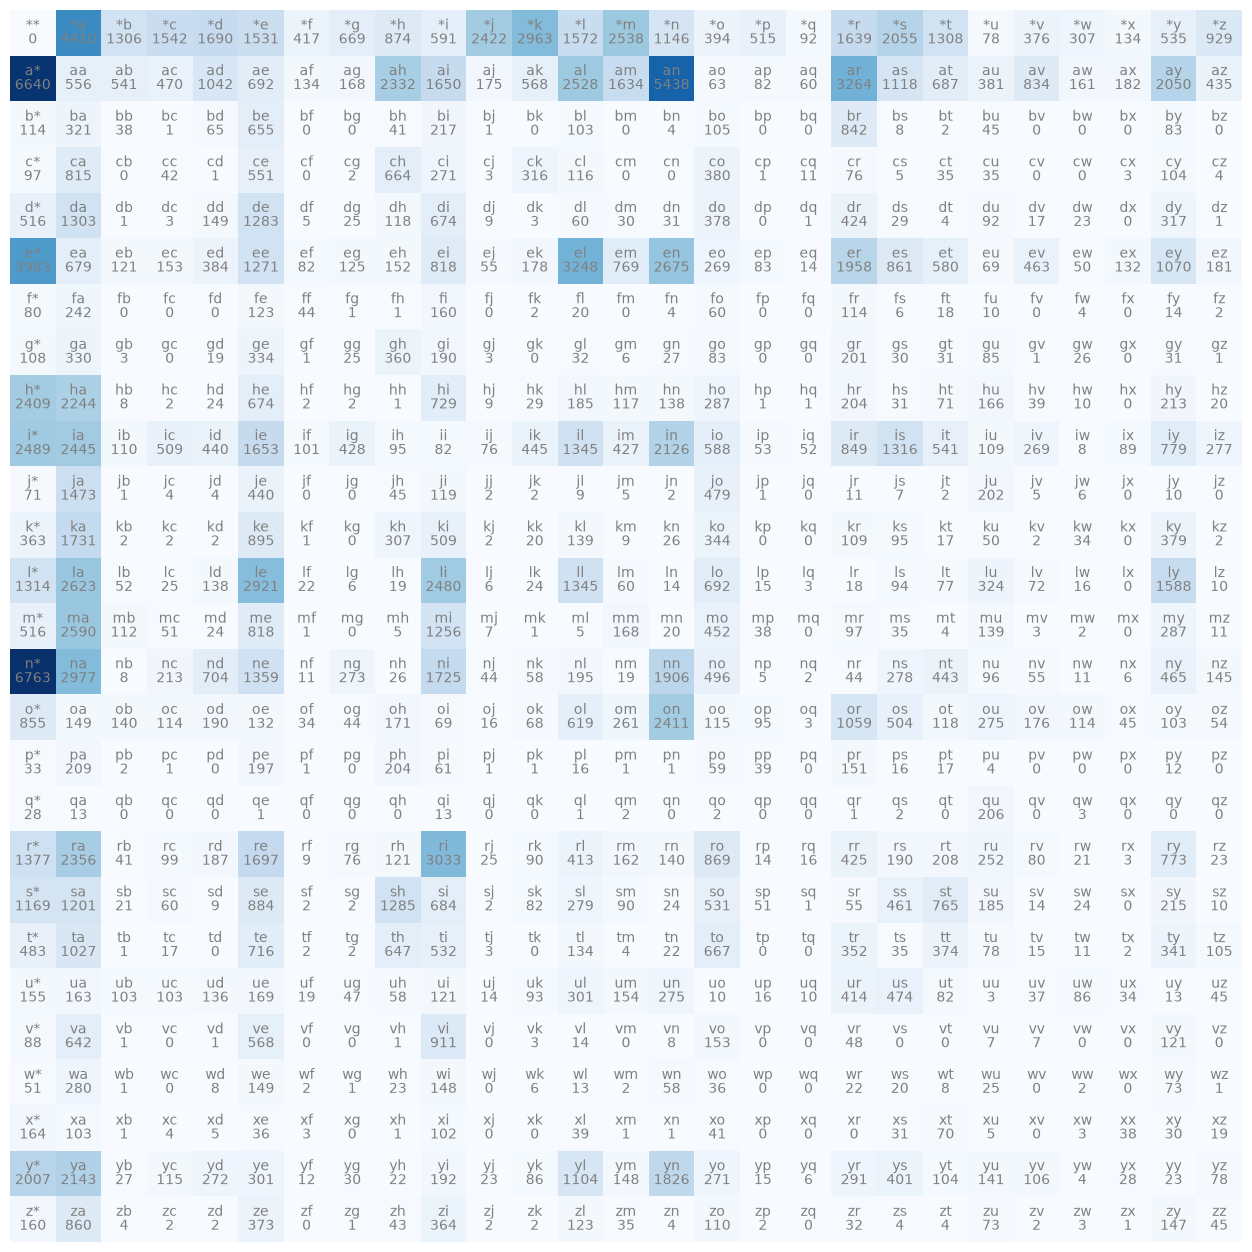

In [118]:

plt.figure(figsize=(16,16))
plt.imshow(N, cmap = "Blues")
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center",va="bottom",color = "gray")
        plt.text(j, i, N[i,j].item(), ha="center",va="top",color = "gray")
plt.axis("off");

In [132]:
N[0]


tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [189]:
p = N[0].float()
p = p / p.sum( )
p


tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [192]:

g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples= 1, replacement = True, generator=g).item()
ix

3

In [171]:
#A deterministic way of creating a torch generator object 

g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator= g)
p = p / p.sum()
p


tensor([0.6064, 0.3033, 0.0903])

In [178]:
torch.multinomial(p, num_samples= 20, replacement = True, generator=g)

tensor([0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1])

In [202]:
p.shape

torch.Size([27])

In [ ]:
g = torch.Generator().manual_seed(2147483647)
for i in range(20):
    out=[]
    ix = 0
    while True:
        #p = N[ix].float()
        #p / p /p.sum()
        p = torch.ones(27)/27 #where everything is equally likely
        ix = torch.multinomial(p, num_samples= 1, replacement = True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break 
    print("".join(out))


cexzm*
zoglkurkicqzktyhwmvmzimjttainrlkfukzkktda*
sfcxvpubjtbhrmgotzx*
iczixqctvujkwptedogkkjemkmmsidguenkbvgynywftbspmhwcivgbvtahlvsu*
dsdxxblnwglhpyiw*
igwnjwrpfdwipkwzkm*
desu*
firmt*
gbiksjbquabsvoth*
kuysxqevhcmrbxmcwyhrrjenvxmvpfkmwmghfvjzxobomysox*
gbptjapxweegpfwhccfyzfvksiiqmvwbhmiwqmdgzqsamjhgamcxwmmk*
iswcxfmbalcslhy*
fpycvasvz*
bqzazeunschck*
wnkojuoxyvtvfiwksddugnkul*
fuwfcgjz*
abl*
j*
nuuutstofgqzubbo*
rdubpknhmd*


In [205]:
g = torch.Generator().manual_seed(2147483647)
for i in range(20):
    out=[]
    ix = 0
    while True:
        p = N[ix].float()
        p / p /p.sum()
        ix = torch.multinomial(p, num_samples= 1, replacement = True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break 
    print("".join(out))

cexze*
momasurailezitynn*
konimittain*
llayn*
ka*
da*
staiyaubrtthrigotai*
moliellavo*
ke*
teda*
ka*
emimmsade*
enkaviyny*
ftlspihinivenvorhlasu*
dsor*
br*
jol*
pen*
aisan*
ja*


In [273]:
P = (N+1).float()

P /= P.sum(1, keepdim=True)

#broadcasting dimesions
P[0].sum()
#print(P.sum(1))
#print(P.sum(1, keepdim=True))

# 27,27
#.  27

tensor(1.)

In [475]:
g = torch.Generator().manual_seed(2147483647)
for i in range(4):
    out=[]
    ix = 0
    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples= 1, replacement = True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break 
    print("".join(out))

cexze*
momasurailezitynn*
konimittain*
llayn*


In [452]:
#evaluating the model 

log_likelihood = 0.0
n = 0

#for w in data[:3]:
for w in ["aysenajx"]: # the loss is infinity 
    chs = ["*"]+ list(w) + ["*"]
    for ch1,ch2 in zip(chs,chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1,ix2]
        logprob = torch.log(prob)
        log_likelihood += logprob

        n+=1

        print(f"{ch1}{ch2}: {prob:.4f}, {logprob:.4f}")

print(f"{log_likelihood=}")
nll = -log_likelihood
print(f"{nll=}")
print(f"{nll/n=}")



*a: 0.1376, -1.9835
ay: 0.0605, -2.8054
ys: 0.0410, -3.1940
se: 0.1088, -2.2181
en: 0.1309, -2.0337
na: 0.1623, -1.8186
aj: 0.0052, -5.2610
jx: 0.0003, -7.9817
x*: 0.2279, -1.4788
log_likelihood=tensor(-28.7749)
nll=tensor(28.7749)
nll/n=tensor(3.1972)


In [474]:
#MAIN


#in his words a respectable bigram model 
#create the training set of all of the bigrams (x,y):

xs, ys = [],[]

for w in data:
    chs = ["*"]+ list(w) + ["*"]
    for ch1,ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)


xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print("number of examples: ", num)

number of examples:  228146


In [461]:
#regularizaiton
(W**2).sum()

tensor(1754.4622, grad_fn=<SumBackward0>)

In [466]:
import torch.nn.functional as F
x_enc = F.one_hot(xs, num_classes=27).float() #floats can feed into NN's




In [333]:
x_enc.shape
#x_enc.dtype #dtype is 64-bit int

torch.Size([5, 27])

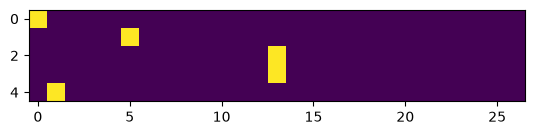

In [315]:
plt.imshow(x_enc)

In [446]:
W = torch.rand((27,1))
print(x_enc @ W) 
print((x_enc @ W).shape)
#(5,27) @ (27,1) -> (5,1)

tensor([[0.4969],
        [0.4708],
        [0.8689],
        [0.8689],
        [0.0290]])
torch.Size([5, 1])


In [467]:

#randomly initialize 27 neurons' weights each neuron receives 27 inputs.
g = torch.Generator().manual_seed(2147483647+1)
W = torch.randn((27,27), generator = g, requires_grad=True)



In [468]:
#MAIN NN

for k in range(100):
    #forward pass
    x_enc = F.one_hot(xs, num_classes=27).float() # input to the network floated one-hot
    logits = x_enc @ W #predict log counts
    counts = logits.exp() # counts equivalent to N
    probs = counts/ counts.sum(1, keepdim=True) #probabilities for the next character

    #probs[0,5], probs[1,13],probs[2,13],probs[3,1],probs[4,0]
    loss = -probs[torch.arange(num),ys].log().mean() + 0.01 *(W**2).mean()

    print(f" {k} the run's loss : {loss}")

    # .exp() o mean = softmax

    #updating weights/backward pass
    W.grad = None
    loss.backward()

    W.data += -50 * W.grad

   


 0 the run's loss : 3.70310640335083
 1 the run's loss : 3.3233892917633057
 2 the run's loss : 3.125629425048828
 3 the run's loss : 2.9990084171295166
 4 the run's loss : 2.907686233520508
 5 the run's loss : 2.840566635131836
 6 the run's loss : 2.7906386852264404
 7 the run's loss : 2.7527413368225098
 8 the run's loss : 2.7231462001800537
 9 the run's loss : 2.6993048191070557
 10 the run's loss : 2.6795639991760254
 11 the run's loss : 2.6628665924072266
 12 the run's loss : 2.64851975440979
 13 the run's loss : 2.6360461711883545
 14 the run's loss : 2.6250953674316406
 15 the run's loss : 2.6153998374938965
 16 the run's loss : 2.606750249862671
 17 the run's loss : 2.598982334136963
 18 the run's loss : 2.591966152191162
 19 the run's loss : 2.585599899291992
 20 the run's loss : 2.5797996520996094
 21 the run's loss : 2.574497938156128
 22 the run's loss : 2.569636583328247
 23 the run's loss : 2.56516695022583
 24 the run's loss : 2.5610463619232178
 25 the run's loss : 2.55

In [426]:
nlls = torch.zeros(5)

for i in range(5):
    #ith bi-gram
    x = xs[i].item()
    y = ys[i].item()
    print("-------")
    print(f"bigram example {i+1}: {itos[x]},{itos[y]} (indexes {x},{y})")
    print("input to the neural net:", y)
    print("output probabilities from the neural net:", probs[i])
    print("label(actual next character):", y)
    p = probs[i,y]
    print("probability assigned by the net to the correct character: ", p.item())
    logp = torch.log(p)
    print("log likelihood: " ,logp.item())
    nll = -logp
    print("negative log likelihood: ", nll.item())
    nlls[i] = nll


print("========")
print("average neagtive log likelihood i.e. loss:", nlls.mean().sum())



-------
bigram example 1: *,e (indexes 0,5)
input to the neural net: 5
output probabilities from the neural net: tensor([0.0049, 0.0955, 0.0280, 0.0701, 0.0957, 0.0596, 0.0241, 0.0135, 0.0093,
        0.1408, 0.0225, 0.0217, 0.0512, 0.0106, 0.0097, 0.0291, 0.0229, 0.0272,
        0.0325, 0.0275, 0.0445, 0.0500, 0.0214, 0.0093, 0.0120, 0.0354, 0.0310],
       grad_fn=<SelectBackward0>)
label(actual next character): 5
probability assigned by the net to the correct character:  0.05955921858549118
log likelihood:  -2.820784091949463
negative log likelihood:  2.820784091949463
-------
bigram example 2: e,m (indexes 5,13)
input to the neural net: 13
output probabilities from the neural net: tensor([0.0426, 0.0113, 0.0266, 0.0508, 0.2355, 0.0581, 0.0421, 0.0095, 0.0136,
        0.0298, 0.0044, 0.0782, 0.1027, 0.0152, 0.0173, 0.0289, 0.0264, 0.0319,
        0.0249, 0.0210, 0.0063, 0.0057, 0.0310, 0.0269, 0.0299, 0.0089, 0.0206],
       grad_fn=<SelectBackward0>)
label(actual next character): 1

In [432]:
print(loss.item())

3.3163864612579346


In [428]:
#updating weights/backward pass
W.grad = None
loss.backward()


In [429]:
W.data += -0.1 * W.grad

In [ ]:
#Sampling from the neural net module

g = torch.Generator().manual_seed(2147483647)

for i in range(10):

    out = []
    ix = 0

    while True: 

        #-----
        #Before
        #p = P[ix]
        #------Now
        x_enc = F.one_hot(torch.tensor([ix]),num_classes=27).float()
        logits = x_enc @ W
        counts = logits.exp()
        p = counts / counts.sum(1,keepdims=True)
        #-------

        ix = torch.multinomial(p,num_samples=1,replacement = True, generator= g).item()
        out.append(itos[ix])
        if ix == 0 :
            break
    print("".join(out))

cexze*
momasurailezityha*
konimittain*
llayn*
ka*
da*
staiyaubrtthrigotai*
moliellavo*
ke*
teda*


1